# 01 EDA: BankSim

Week 1 walkthrough. The plotting code lives in `src/eda.py`; this notebook loads the cleaned data and shows the key numbers and figures.

Run `./run_week1.sh` from the repo root first.

In [1]:
import os, sys
os.chdir('..') if os.path.basename(os.getcwd()) == 'notebooks' else None
sys.path.insert(0, '.')

import pandas as pd
from IPython.display import Image, display
from src.config import CLEAN_FILE, FIG_DIR, TABLE_DIR

df = pd.read_parquet(CLEAN_FILE)
df.head()

,txn_id,step,customer,age,gender,merchant,category,amount,fraud,log_amount,zero_amount
0,0,0,C1093826151,4,M,M348934600,transportation,4.55,0,1.713798,0
1,1,0,C352968107,2,M,M348934600,transportation,39.68,0,3.705737,0
2,2,0,C2054744914,4,F,M1823072687,transportation,26.89,0,3.328268,0
3,3,0,C1760612790,3,M,M348934600,transportation,17.25,0,2.904165,0
4,4,0,C757503768,5,M,M348934600,transportation,35.72,0,3.603322,0


In [2]:
print(df.shape)
print('fraud rate:', round(df.fraud.mean(), 4))
df.describe(include='all').T

(594643, 11)
fraud rate: 0.0121


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
txn_id,594643.0,NaN,NaN,NaN,297321.0,171658.792398,0.0,148660.5,297321.0,445981.5,594642.0
step,594643.0,NaN,NaN,NaN,94.986827,51.053632,0.0,52.0,97.0,139.0,179.0
customer,594643,4112,C1978250683,265,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,594643,8,2,187310,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,594643,4,F,324565,NaN,NaN,NaN,NaN,NaN,NaN,NaN
merchant,594643,50,M1823072687,299693,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,594643,15,transportation,505119,NaN,NaN,NaN,NaN,NaN,NaN,NaN
amount,594643.0,NaN,NaN,NaN,37.890135,111.402831,0.0,13.74,26.9,42.54,8329.96
fraud,594643.0,NaN,NaN,NaN,0.012108,0.109369,0.0,0.0,0.0,0.0,1.0
log_amount,594643.0,NaN,NaN,NaN,3.176207,0.955484,0.0,2.690565,3.328627,3.77368,9.027734


## Split
Chronological: train = days 0-119, val = 120-149, test = 150-179.

In [3]:
pd.read_csv(TABLE_DIR / 'split_summary.csv')

,split,steps,n_days,n_txns,n_fraud,fraud_rate,n_customers,n_merchants,n_categories_with_fraud
0,train,0-119,120,374914,4800,0.01280,4111,50,12
1,val,120-149,30,108423,1200,0.01107,4070,50,12
2,test,150-179,30,111306,1200,0.01078,4079,49,12


In [4]:
pd.read_csv(TABLE_DIR / 'split_overlap.csv')

,split,customers_not_in_train,txns_from_unseen_customers,merchants_not_in_train,txns_at_unseen_merchants
0,val,1,2,0,0
1,test,1,3,0,0


## Over time
Fraud is exactly 40 rows per day (a simulator artifact) while volume grows, so the fraud rate drifts down.

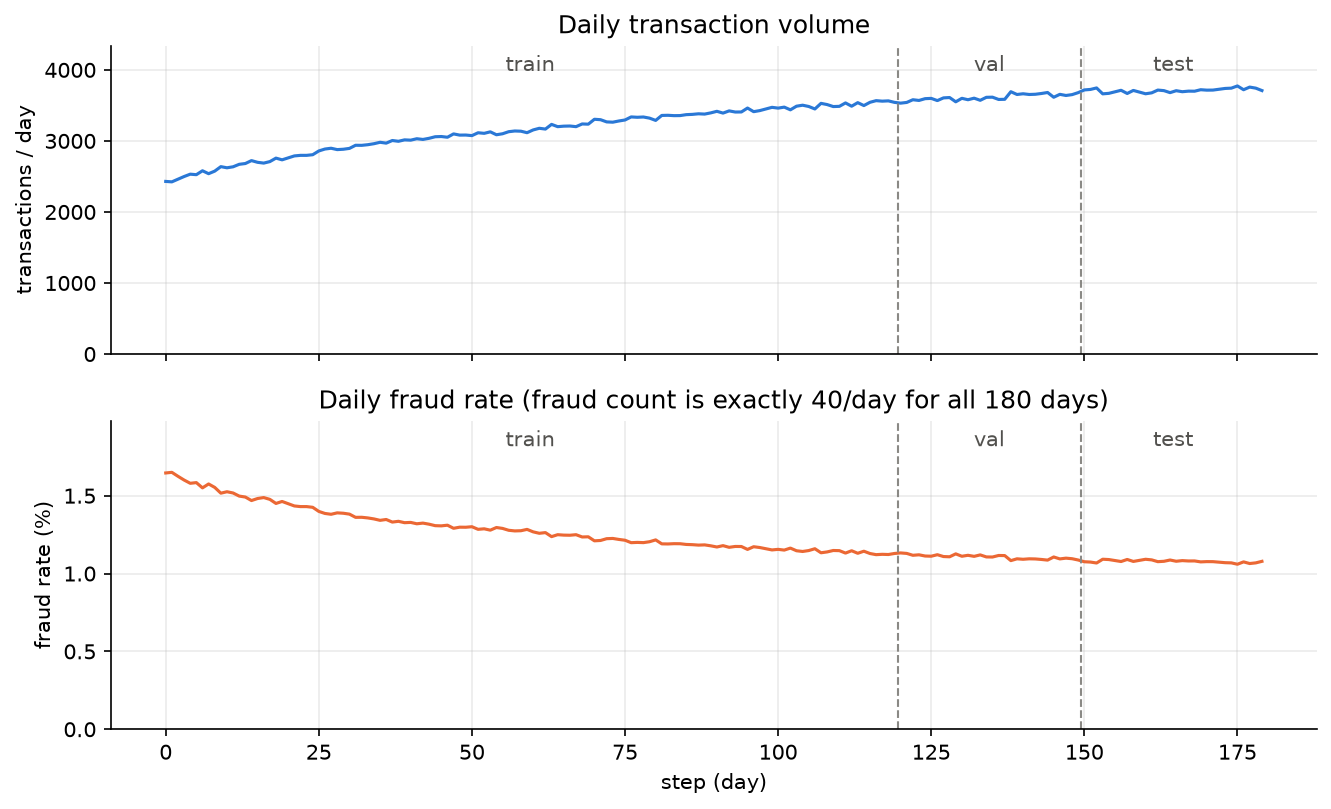

In [5]:
display(Image(FIG_DIR / '01_volume_and_fraud_over_time.png'))

## Amount

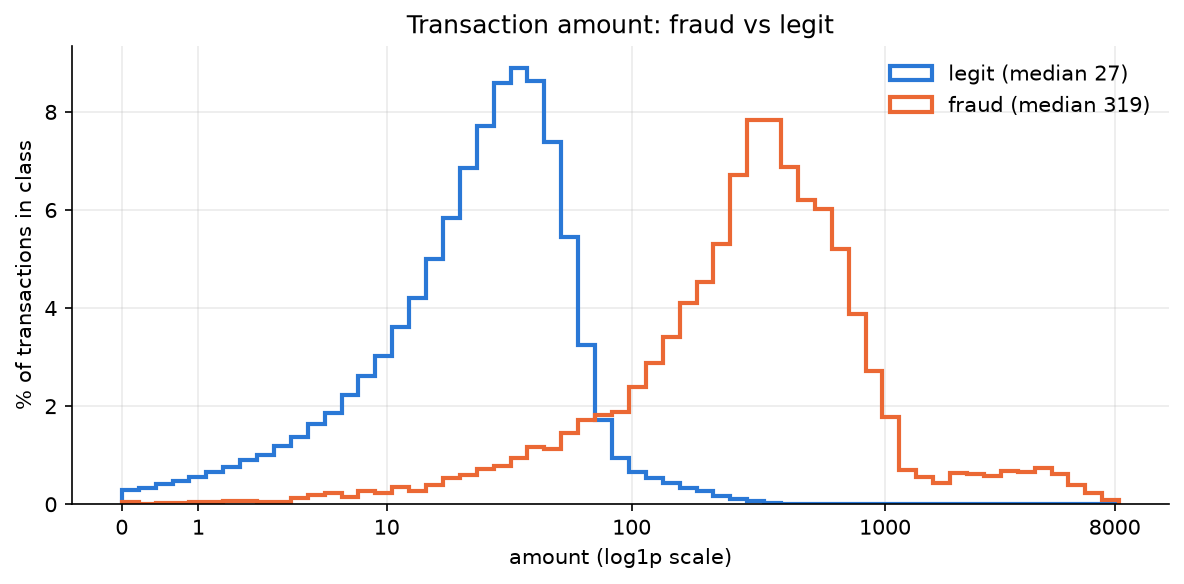

,count,mean,std,min,25%,50%,75%,max
fraud,,,,,,,,
0,587443.0,31.847230,31.470876,0.00,13.59,26.610,41.8950,2144.86
1,7200.0,530.926551,835.587112,0.03,159.98,319.175,548.9775,8329.96


In [6]:
display(Image(FIG_DIR / '02_amount_distribution.png'))
df.groupby('fraud').amount.describe()

## Category

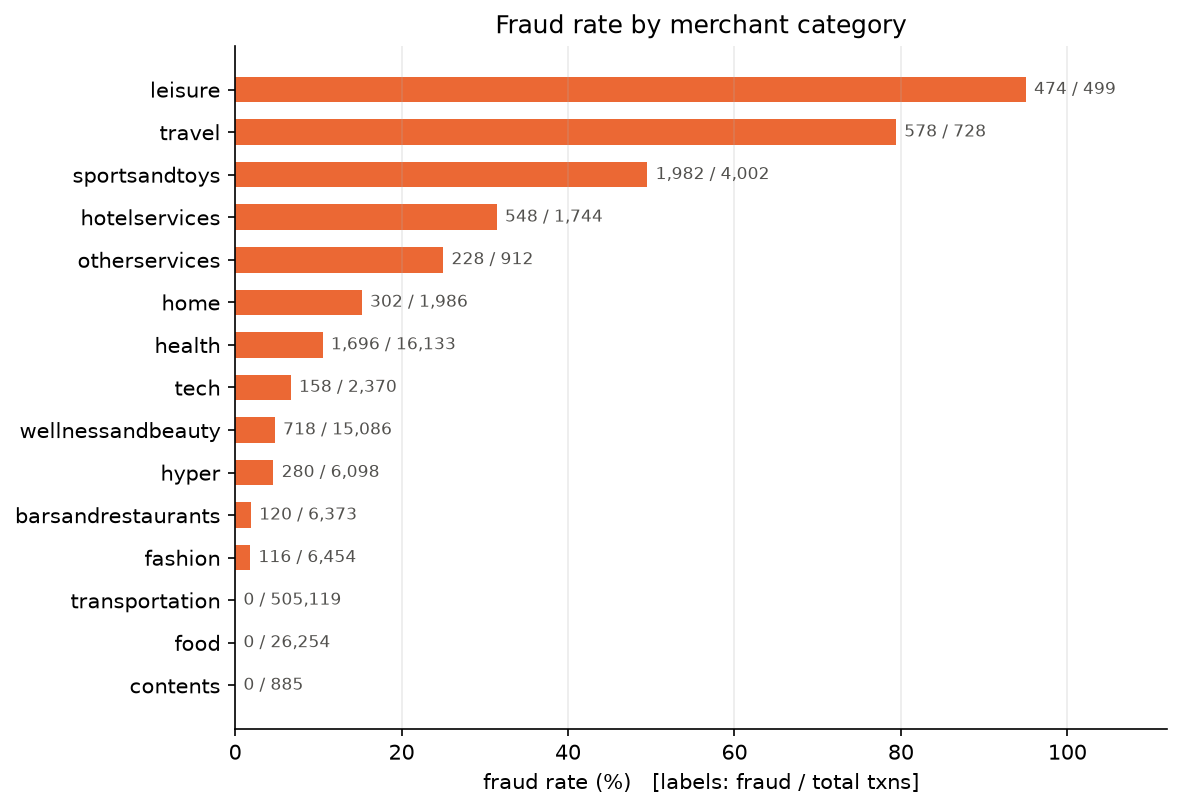

,category,n_txns,n_fraud,fraud_rate,median_amount,share_of_all_fraud
0,leisure,499,474,0.9499,296.660,0.0658
1,travel,728,578,0.7940,1888.460,0.0803
2,sportsandtoys,4002,1982,0.4953,134.175,0.2753
3,hotelservices,1744,548,0.3142,131.940,0.0761
4,otherservices,912,228,0.2500,87.280,0.0317
5,home,1986,302,0.1521,111.310,0.0419
6,health,16133,1696,0.1051,97.890,0.2356
7,tech,2370,158,0.0667,90.390,0.0219
8,wellnessandbeauty,15086,718,0.0476,51.895,0.0997
9,hyper,6098,280,0.0459,36.750,0.0389


In [7]:
display(Image(FIG_DIR / '03_fraud_rate_by_category.png'))
pd.read_csv(TABLE_DIR / 'category_summary.csv')

## Age and gender

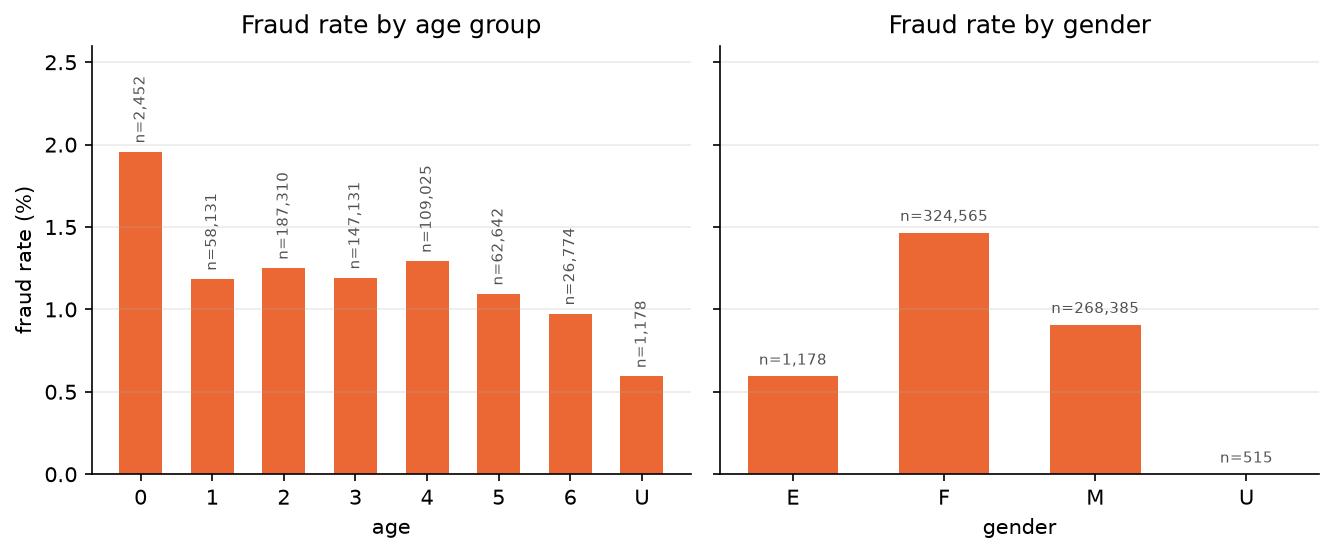

In [8]:
display(Image(FIG_DIR / '04_fraud_rate_by_age_gender.png'))

## Merchants and customers
Merchant identity is close to a label, so any merchant fraud-rate feature has to be computed from earlier days only.

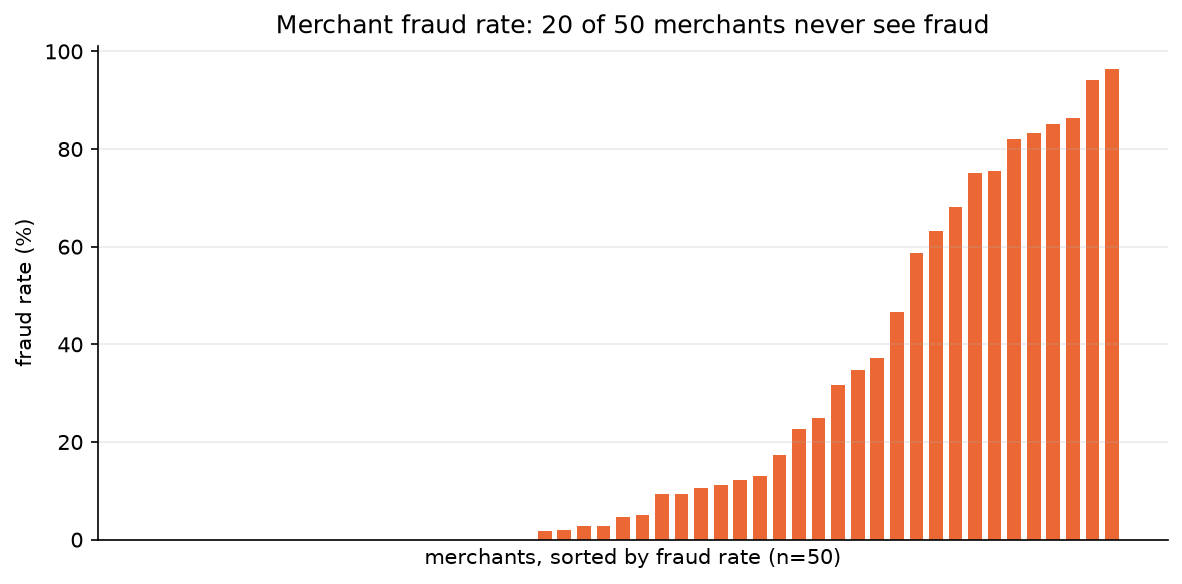

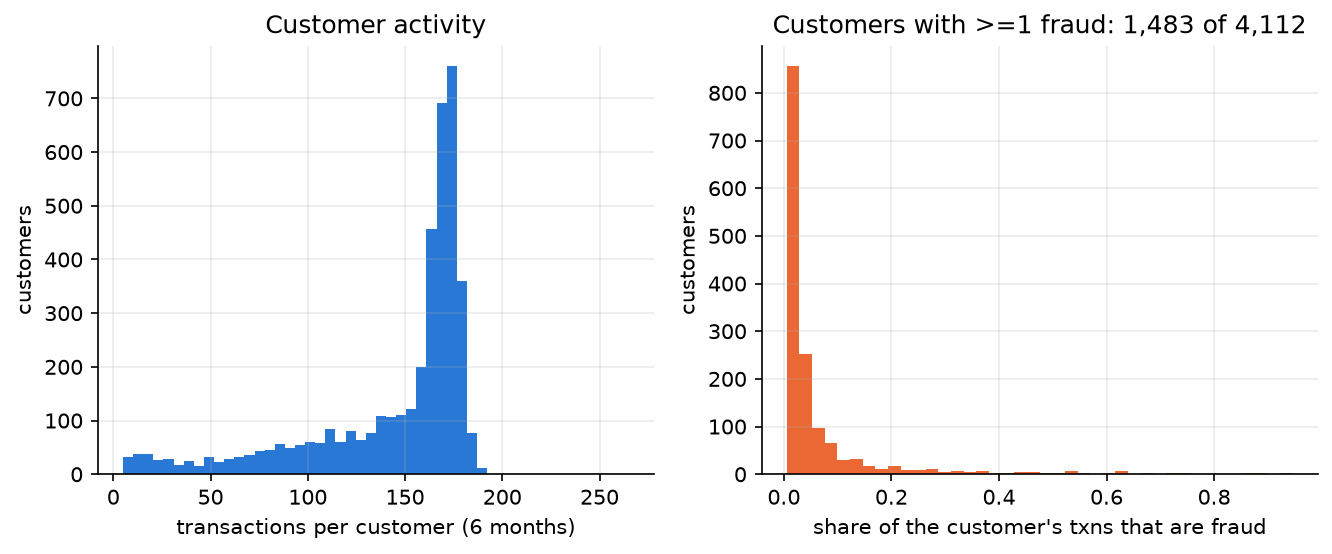

In [9]:
display(Image(FIG_DIR / '05_merchant_fraud_rate.png'))
display(Image(FIG_DIR / '06_customer_activity.png'))

## Normal-looking fraud subgroup
Definition in `docs/subgroup_definition.md` (amount <= train legit P95 of the same category).

In [10]:
pd.read_csv(TABLE_DIR / 'subgroup_sizes.csv')

,split,n_fraud,normal_looking_fraud,pct_of_fraud,normal_looking_legit,strict_normal_looking_fraud,strict_pct_of_fraud
0,train,4800,1478,30.8,351610,547,11.4
1,val,1200,395,32.9,101847,149,12.4
2,test,1200,400,33.3,104736,164,13.7


## Normal-looking fraud vs normal-looking legit
Does fraud that looks ordinary on its amount also look ordinary on its history? Train days only (0–119). "Same-category legit" reweights the legit rows to the fraud's category mix, so a category difference isn't mistaken for a history difference. Differences are in standard deviations (fraud mean minus legit mean, over the pooled sd; under 0.2 is small). Code: `normal_looking_section()` in `src/eda.py`. Tables: `normal_looking_comparison.csv`, `normal_looking_category_mix.csv`.

What it shows:
- **Category is not ordinary.** 31% of normal-looking fraud is sportsandtoys and 26% is health, against 0.4% and 2.3% of normal-looking legit. 90% of normal-looking legit is transportation, food or contents, which never see fraud. Category alone still gives much of this subgroup away (see the caveat in `docs/subgroup_definition.md`).
- **Amount within its category overlaps** (0.15 sd above same-category legit), though fraud sits a little higher inside the cut.
- **"New merchant" and "unusual spend" don't survive matching on category.** Against all normal-looking legit, fraud is far more often a first visit to the merchant. Against legit in the same categories it is *less* often one (57% vs 75%), and less of a jump from the customer's usual amount.
- **What does survive:** the merchant's known fraud rate and the customer's known past fraud (G5, past labels); repeat transactions on the same customer–merchant pair (G3); victims having paid more distinct merchants before, and slightly fewer past transactions (G1, the `g1_cust_n_prev` effect).

So on this subgroup, the case for graph features rests mostly on past labels and repeat-victim patterns, not on new pairs or sudden changes in spending. R2's label-free vs labels-only ablation tests how much of the gain is G5.

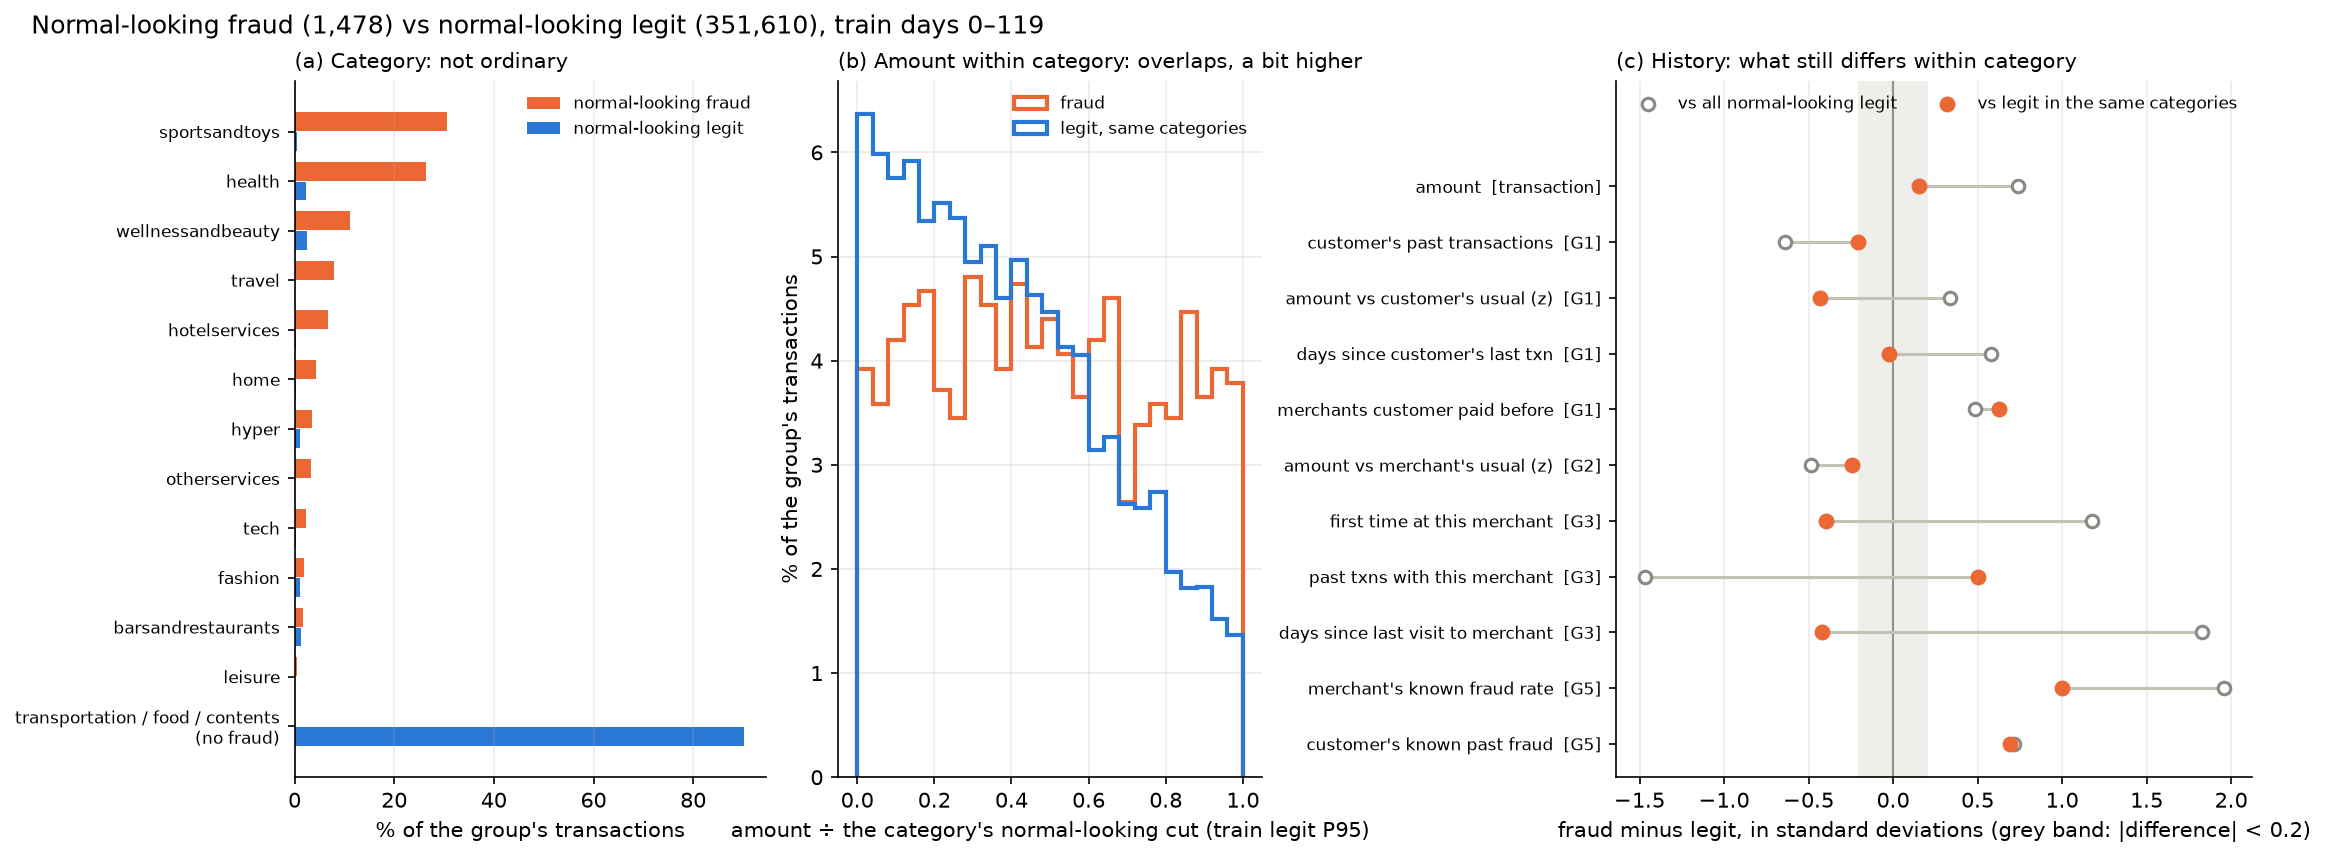

,label,group,nl_fraud_mean,nl_legit_mean,nl_legit_same_category_mean,smd_vs_nl_legit,smd_vs_same_category_legit
0,amount,transaction,157.565,29.187,123.321,0.738,0.154
1,customer's past transactions,G1 customer,31.149,51.705,37.902,-0.642,-0.205
2,amount vs customer's usual (z),G1 customer,0.547,-0.103,1.763,0.340,-0.433
3,days since customer's last txn,G1 customer,5.246,1.588,5.433,0.580,-0.022
4,merchants customer paid before,G1 customer,8.033,5.739,5.013,0.483,0.626
5,amount vs merchant's usual (z),G2 merchant,-0.464,-0.130,-0.316,-0.483,-0.246
6,first time at this merchant,G3 pair,0.568,0.092,0.752,1.177,-0.396
7,past txns with this merchant,G3 pair,1.948,27.953,0.379,-1.468,0.500
8,days since last visit to merchant,G3 pair,23.269,4.915,27.111,1.827,-0.419
9,merchant's known fraud rate,G5 past labels,0.391,0.005,0.140,1.955,1.001


In [11]:
display(Image(FIG_DIR / '07_normal_looking_fraud_vs_legit.png'))
cols = ['label', 'group', 'nl_fraud_mean', 'nl_legit_mean', 'nl_legit_same_category_mean',
        'smd_vs_nl_legit', 'smd_vs_same_category_legit']
pd.read_csv(TABLE_DIR / 'normal_looking_comparison.csv')[cols].round(3)